ps_test{200}.mat: Hellinger = 0.049730
ps_test{9}.mat: Hellinger = 0.052982
PDF saved: four_gene_test_marginal_distribution_selected_samples.pdf


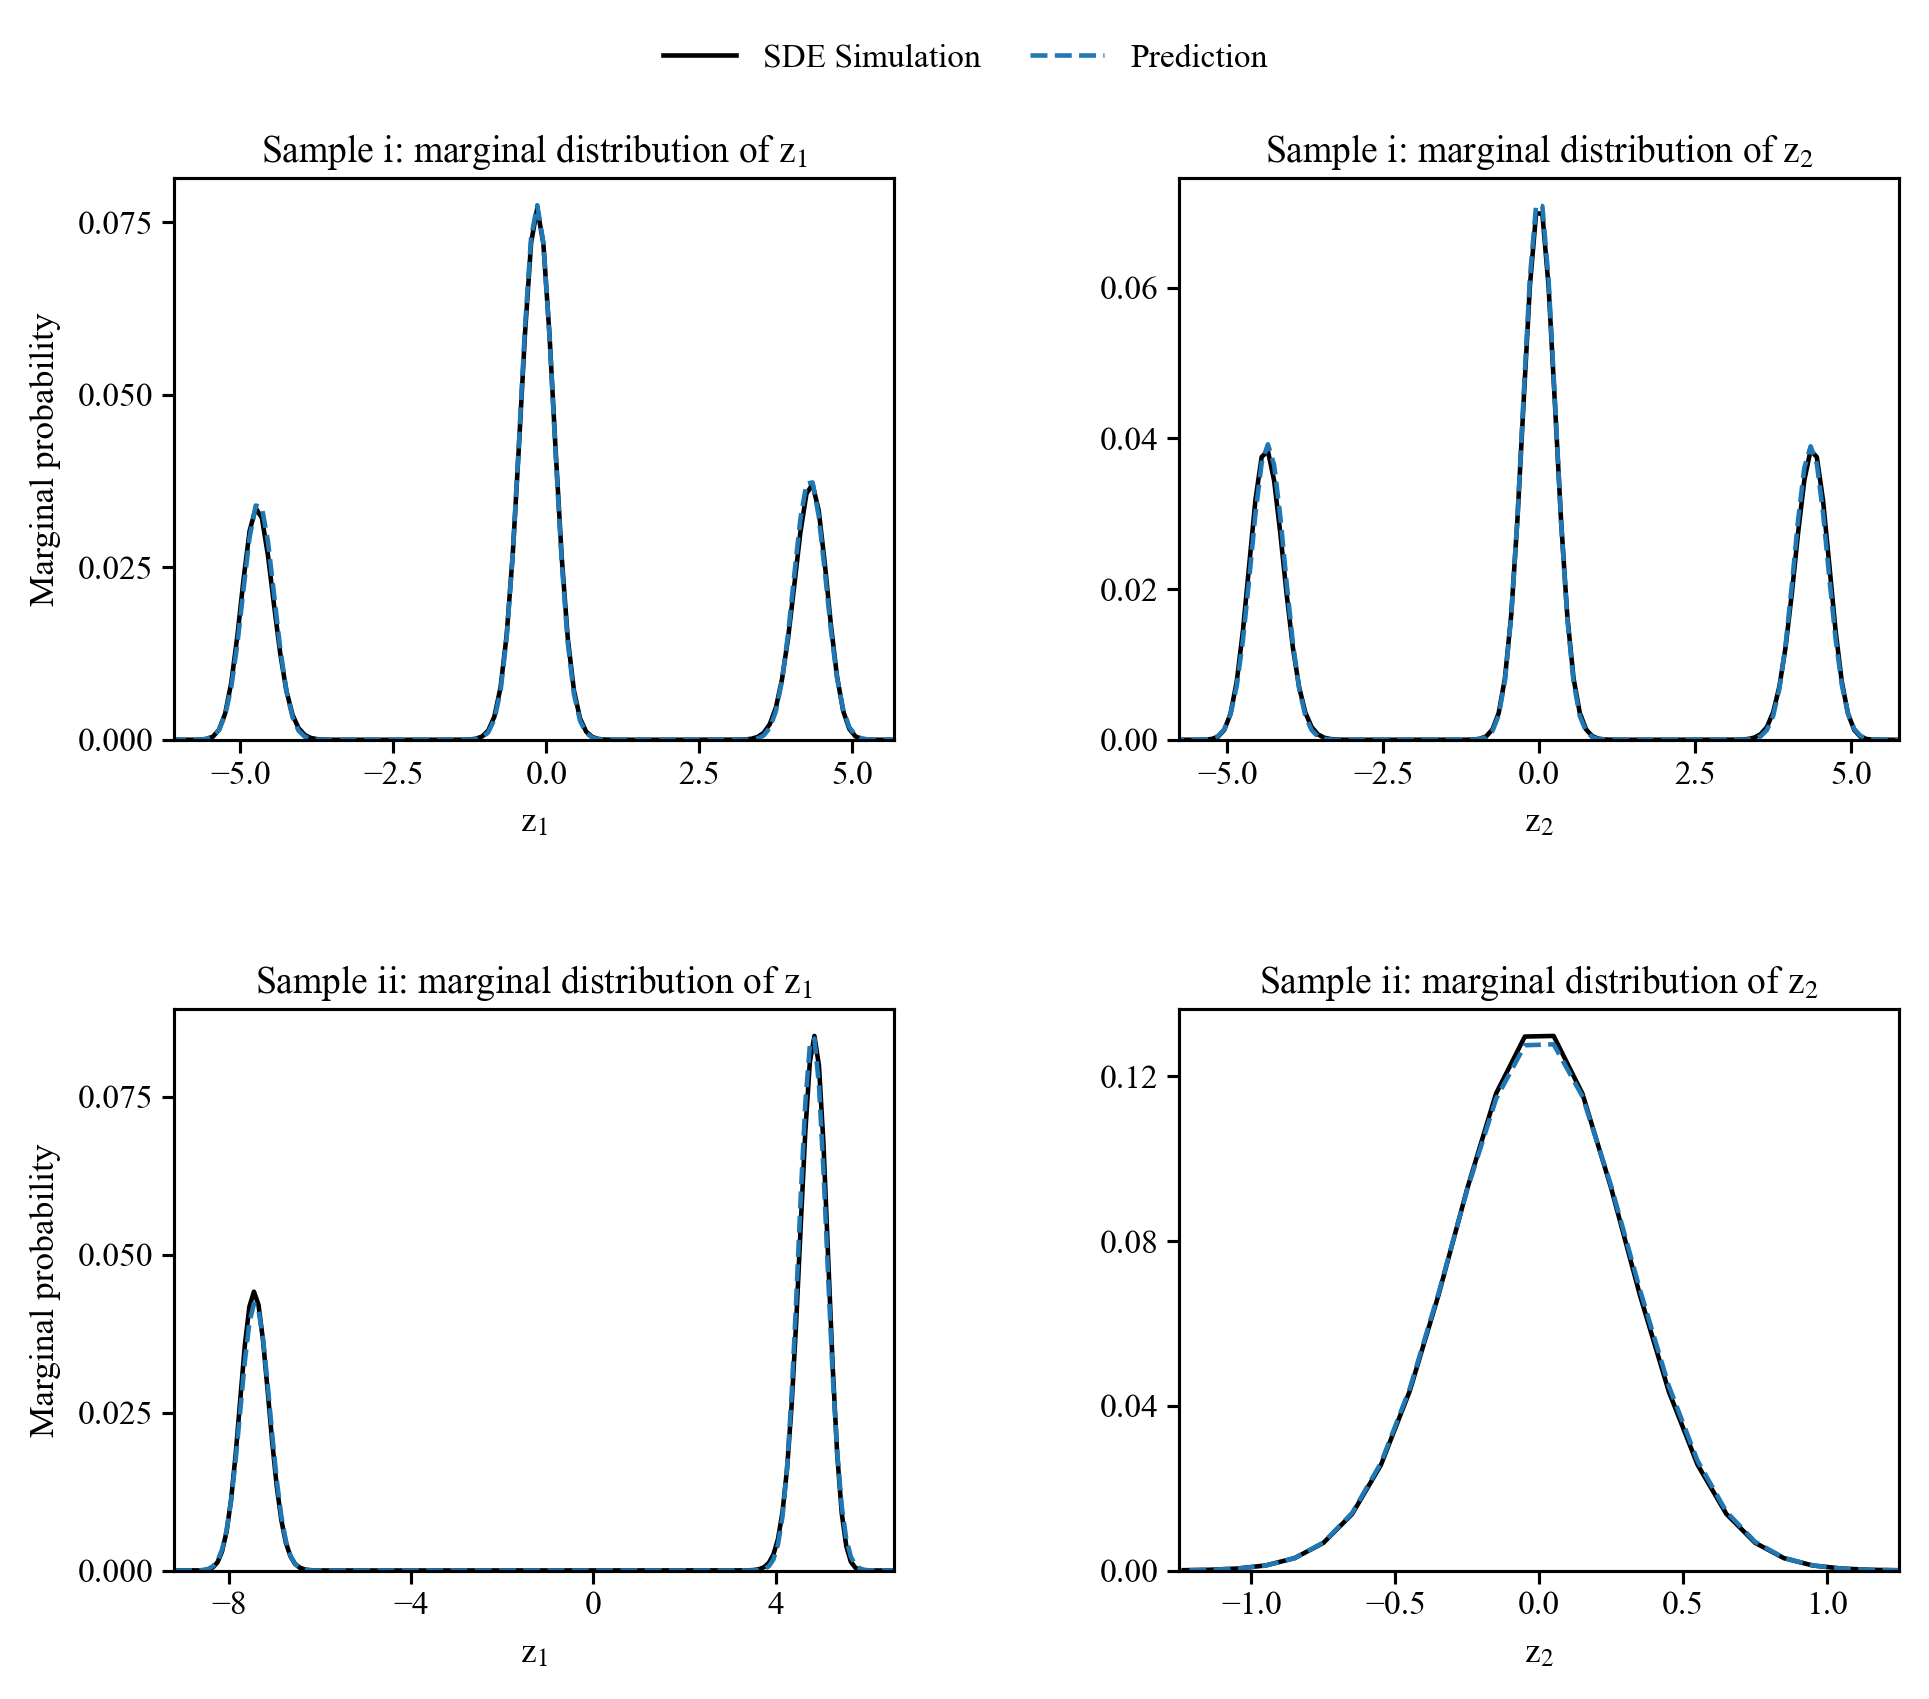

In [7]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy.io import loadmat
from matplotlib.ticker import MaxNLocator

plt.rcParams.update({
    "font.family": "Times New Roman", "mathtext.fontset": "stix",
    "font.size": 8.5, "axes.labelsize": 8.5, "axes.titlesize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.linewidth": 0.75, "xtick.direction": "out",
    "ytick.direction": "out", "figure.dpi": 300, "savefig.dpi": 600,
    "pdf.fonttype": 42, "ps.fonttype": 42
})


class MixtureOfGaussiansModel(nn.Module):
    def __init__(self, input_dim=5, k=4, hidden=(512, 1024, 512)):
        super().__init__()
        self.k = k
        dims = [input_dim, *hidden]
        self.hidden_layers = nn.ModuleList(
            nn.Linear(dims[i], dims[i + 1]) for i in range(len(dims) - 1)
        )
        self.output_layer = nn.Linear(hidden[-1], 6 * k)

    def forward(self, x):
        for layer in self.hidden_layers:
            x = F.relu(layer(x))
        z = self.output_layer(x).view(-1, self.k, 6)
        w, mu = F.softmax(z[:, :, 0], 1), z[:, :, 1:3]
        s11 = F.softplus(z[:, :, 3]) + 1e-6
        rho = torch.clamp(2 * torch.sigmoid(z[:, :, 4]) - 1,
                          -1 + 1e-4, 1 - 1e-4)
        s22 = F.softplus(z[:, :, 5]) + 1e-6
        s12 = rho * torch.sqrt(s11 * s22)

        cov = torch.zeros(x.size(0), self.k, 2, 2,
                          dtype=x.dtype, device=x.device)
        cov[:, :, 0, 0], cov[:, :, 0, 1] = s11, s12
        cov[:, :, 1, 0], cov[:, :, 1, 1] = s12, s22
        return w, mu, cov


# ======================== 可修改参数 ========================
MODEL_PATH = "best_model_in5_K4_512-1024-512_testloss0.084797.pth"
CSV_TEST = "ps_test.csv"
MAT_TEST_DIR = "density_results_ps_test_n_cells=50000_python_edges=0.1"
SELECTED_SAMPLE_INDICES = "200,9"

GRID_STEP = 0.1
X_MIN = Y_MIN = -10.3

# 每个子图独立自适应横坐标
X_MASS = 0.999       # 保留99.9%的主要概率质量
X_PADDING = 0.06     # 横坐标两端留白比例
BOX_ASPECT = 0.78    # 子图高度/宽度；1.0为正方形

SAVE_FIG = True
OUT_PDF = "four_gene_test_marginal_distribution_selected_samples.pdf"


def load_model(device):
    model = MixtureOfGaussiansModel().to(device)
    try:
        state = torch.load(MODEL_PATH, map_location=device, weights_only=True)
    except TypeError:
        state = torch.load(MODEL_PATH, map_location=device)
    model.load_state_dict(state)
    model.eval()
    return model


def find_max_n():
    sizes = []
    for name in os.listdir(MAT_TEST_DIR):
        if name.startswith("ps_test{") and name.endswith(".mat"):
            sizes.append(max(loadmat(os.path.join(MAT_TEST_DIR, name))
                             ["density"].shape))
    if not sizes:
        raise FileNotFoundError(f"{MAT_TEST_DIR}中未找到测试集MAT文件。")
    return max(sizes)


def parse_ids(text, n):
    ids = list(dict.fromkeys(int(v.strip()) for v in text.split(",")
                             if v.strip()))
    if not ids or any(i < 1 or i > n for i in ids):
        raise ValueError(f"样本编号必须位于1到{n}。")
    return ids


def roman(n):
    table = ((1000, "m"), (900, "cm"), (500, "d"), (400, "cd"),
             (100, "c"), (90, "xc"), (50, "l"), (40, "xl"),
             (10, "x"), (9, "ix"), (5, "v"), (4, "iv"), (1, "i"))
    out = ""
    for value, symbol in table:
        while n >= value:
            out += symbol
            n -= value
    return out


def normalize(p):
    p = p + 1e-8
    return p / p.sum((1, 2), keepdim=True)


def load_true_density(sample_id, max_n, device):
    path = os.path.join(MAT_TEST_DIR, f"ps_test{{{sample_id}}}.mat")
    p = np.asarray(loadmat(path)["density"], dtype=np.float32)
    py, px = max_n - p.shape[0], max_n - p.shape[1]
    if py < 0 or px < 0:
        raise ValueError(f"{path}的矩阵尺寸大于max_n={max_n}。")
    p = np.pad(p, ((0, py), (0, px)))
    return normalize(torch.tensor(p, device=device)[None])


@torch.no_grad()
def predicted_density(w, mu, cov, gx, gy):
    m1, m2 = mu[:, :, 0, None, None], mu[:, :, 1, None, None]
    s11 = cov[:, :, 0, 0, None, None]
    s12 = cov[:, :, 0, 1, None, None]
    s22 = cov[:, :, 1, 1, None, None]
    det = torch.clamp(s11 * s22 - s12 ** 2, min=1e-12)

    d1, d2 = gx[None, None] - m1, gy[None, None] - m2
    exponent = -0.5 * (s22 / det * d1 ** 2
                       - 2 * s12 / det * d1 * d2
                       + s11 / det * d2 ** 2)
    gaussian = torch.exp(exponent) / (2 * torch.pi * torch.sqrt(det))
    return normalize((w[:, :, None, None] * gaussian).sum(1))


def hellinger(p, q):
    return torch.sqrt(0.5 * ((torch.sqrt(p) - torch.sqrt(q)) ** 2).sum()).item()


def adaptive_xlim(x, true_y, pred_y):
    p = np.maximum(true_y, 0) + np.maximum(pred_y, 0)
    if p.sum() <= 0:
        return float(x[0]), float(x[-1])

    cdf = np.cumsum(p / p.sum())
    tail = (1 - X_MASS) / 2
    left = np.clip(np.searchsorted(cdf, tail), 0, len(x) - 1)
    right = np.clip(np.searchsorted(cdf, 1 - tail), left, len(x) - 1)

    step = float(x[1] - x[0])
    width = max(float(x[right] - x[left]), 4 * step)
    pad = max(X_PADDING * width, 2 * step)
    return max(float(x[0]), float(x[left] - pad)), \
           min(float(x[-1]), float(x[right] + pad))


# ======================== 计算所选样本 ========================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
test_df = pd.read_csv(CSV_TEST)
sample_ids = parse_ids(SELECTED_SAMPLE_INDICES, len(test_df))
max_n = find_max_n()

centers = torch.arange(max_n, dtype=torch.float32, device=device)
centers = centers * GRID_STEP + GRID_STEP / 2
grid_x, grid_y = torch.meshgrid(centers, centers, indexing="ij")
x1 = centers.cpu().numpy() + X_MIN
x2 = centers.cpu().numpy() + Y_MIN

model = load_model(device)
results = []

for sample_id in sample_ids:
    params = test_df.iloc[sample_id - 1, :5].to_numpy(dtype=np.float32)
    inputs = torch.tensor(params[None], device=device)
    true = load_true_density(sample_id, max_n, device)

    with torch.no_grad():
        pred = predicted_density(*model(inputs), grid_x, grid_y)

    # density[i,j]对应P(x1_i,x2_j)
    results.append({
        "true_x1": true.sum(2)[0].cpu().numpy(),
        "pred_x1": pred.sum(2)[0].cpu().numpy(),
        "true_x2": true.sum(1)[0].cpu().numpy(),
        "pred_x2": pred.sum(1)[0].cpu().numpy()
    })
    print(f"ps_test{{{sample_id}}}.mat: "
          f"Hellinger = {hellinger(true, pred):.6f}")


# ======================== 绘图 ========================
rows = len(results)
fig, axes = plt.subplots(rows, 2, figsize=(6.8, 2.9 * rows),
                         squeeze=False)
fig.subplots_adjust(left=0.09, right=0.98, bottom=0.09, top=0.89,
                    wspace=0.24, hspace=0.48)

for row, result in enumerate(results):
    sample = f"Sample {roman(row + 1)}"
    curves = (
        (x1, result["true_x1"], result["pred_x1"], r"$\mathrm{z}_1$"),
        (x2, result["true_x2"], result["pred_x2"], r"$\mathrm{z}_2$")
    )

    for col, (coord, true_y, pred_y, variable) in enumerate(curves):
        ax = axes[row, col]
        ax.plot(coord, true_y, color="black", lw=1.1,
                label="SDE Simulation")
        ax.plot(coord, pred_y, color="#1f77b4", lw=1.1, ls="--",
                label="Prediction")

        ax.set_title(f"{sample}: marginal distribution of {variable}", pad=4)
        ax.set_xlabel(variable)
        ax.set_xlim(adaptive_xlim(coord, true_y, pred_y))
        ax.set_ylim(0, 1.05 * max(true_y.max(), pred_y.max()))

        if hasattr(ax, "set_box_aspect"):
            ax.set_box_aspect(BOX_ASPECT)

        ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
        ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
        ax.tick_params(direction="out", length=3, width=0.75, pad=2)

    axes[row, 0].set_ylabel("Marginal probability")

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center",
           bbox_to_anchor=(0.5, 0.985), ncol=2, frameon=False,
           handlelength=2.2, columnspacing=1.5)

if SAVE_FIG:
    fig.savefig(OUT_PDF, format="pdf", bbox_inches="tight")
    print(f"PDF saved: {OUT_PDF}")

plt.show()